# Data AI Job Market Intelligence — Coleta e análise inicial

Este notebook constrói uma primeira versão reproduzível do pipeline de vagas de Dados e Inteligência Artificial no Brasil. A fonte é a API da Adzuna, consultada pelo termo **`data`**.

> **Escopo:** os resultados descrevem apenas a amostra coletada. Eles não representam todo o mercado brasileiro de trabalho.

## 1. Configuração do ambiente

As credenciais são lidas exclusivamente do arquivo local `.env`. Pastas de dados e figuras são criadas de forma idempotente.

In [1]:
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit
import os
import time
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
import requests
from dotenv import load_dotenv
from matplotlib.ticker import MaxNLocator

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

for directory in (DATA_RAW_DIR, DATA_PROCESSED_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

ANO_ANALISE = 2026
TERMO_BUSCA = "data"
PAGINAS = 3
RESULTADOS_POR_PAGINA = 50

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 10,
})

## 2. Piloto inicial da estrutura de dados

Antes da automação, três vagas foram cadastradas manualmente para validar a estrutura do dataset. O piloto é mantido como registro metodológico, sem dominar o fluxo principal.

In [2]:
vagas_piloto = [
    {
        "titulo": "Estágio em Análise de Dados",
        "empresa": "Kasznar Leonardos",
        "localizacao": "Rio de Janeiro, RJ",
        "modalidade": "Não informado",
        "senioridade": "Estágio",
        "descricao": "Manuseio de planilhas, análise e cruzamento de dados; Power BI e VBA como diferenciais.",
        "fonte": "LinkedIn",
        "url": "https://br.linkedin.com/jobs/view/est%C3%A1gio-em-an%C3%A1lise-de-dados-at-kasznar-leonardos-4474859558",
        "data_coleta": "2026-10-18",
        "tipo_contrato": "Não informado",
        "data_publicacao": "Não informado",
    },
    {
        "titulo": "Analista de Dados Junior",
        "empresa": "CashGO",
        "localizacao": "Brasil",
        "modalidade": "Remoto",
        "senioridade": "Júnior",
        "descricao": "Coleta e organização de dados, dashboards em Power BI, SQL, Excel e Python.",
        "fonte": "LinkedIn",
        "url": "https://br.linkedin.com/jobs/view/analista-de-dados-junior-at-cashgo-4474632923",
        "data_coleta": "2026-10-18",
        "tipo_contrato": "PJ",
        "data_publicacao": "2026-10-10",
    },
    {
        "titulo": "Cientista de Dados Júnior",
        "empresa": "Bwtech",
        "localizacao": "Belo Horizonte e Região, MG",
        "modalidade": "Não informado",
        "senioridade": "Júnior",
        "descricao": "Ciência de Dados, Machine Learning, preparação de dados e modelos preditivos.",
        "fonte": "LinkedIn",
        "url": "https://br.linkedin.com/jobs/view/cientista-de-dados-j%C3%BAnior-at-bwtech-4456417958",
        "data_coleta": "2026-10-18",
        "tipo_contrato": "Não informado",
        "data_publicacao": "Não informado",
    },
]


jobs_pilot = pd.DataFrame(vagas_piloto)
jobs_pilot.to_csv(DATA_RAW_DIR / "jobs_pilot.csv", index=False)
jobs_pilot.head(3)

,titulo,empresa,localizacao,modalidade,senioridade,descricao,fonte,url,data_coleta,tipo_contrato,data_publicacao
0,Estágio em Análise de Dados,Kasznar Leonardos,"Rio de Janeiro, RJ",Não informado,Estágio,"Manuseio de planilhas, análise e cruzamento de...",LinkedIn,https://br.linkedin.com/jobs/view/est%C3%A1gio...,2026-10-18,Não informado,Não informado
1,Analista de Dados Junior,CashGO,Brasil,Remoto,Júnior,"Coleta e organização de dados, dashboards em P...",LinkedIn,https://br.linkedin.com/jobs/view/analista-de-...,2026-10-18,PJ,2026-10-10
2,Cientista de Dados Júnior,Bwtech,"Belo Horizonte e Região, MG",Não informado,Júnior,"Ciência de Dados, Machine Learning, preparação...",LinkedIn,https://br.linkedin.com/jobs/view/cientista-de...,2026-10-18,Não informado,Não informado


## 3. Autenticação da API

O `.env` deve conter `ADZUNA_APP_ID` e `ADZUNA_APP_KEY`. Os valores nunca são exibidos no notebook.

In [3]:
load_dotenv(PROJECT_ROOT / ".env", override=True)

app_id = os.getenv("ADZUNA_APP_ID")
app_key = os.getenv("ADZUNA_APP_KEY")

if not app_id or not app_key:
    raise RuntimeError(
        "Credenciais ausentes. Configure ADZUNA_APP_ID e ADZUNA_APP_KEY no arquivo .env."
    )

print("Credenciais carregadas do .env com sucesso.")

Credenciais carregadas do .env com sucesso.


## 4. Primeiro teste de conexão com a API

Uma única página é consultada para validar a conexão e inspecionar a estrutura, sem exibir URLs ou parâmetros sensíveis.

In [4]:
def buscar_pagina(pagina, termo, resultados_por_pagina, app_id, app_key):
    url = f"https://api.adzuna.com/v1/api/jobs/br/search/{pagina}"
    params = {
        "app_id": app_id,
        "app_key": app_key,
        "results_per_page": resultados_por_pagina,
        "what": termo,
    }

    for tentativa in range(1, 4):
        try:
            response = requests.get(url, params=params, timeout=30)
            response.raise_for_status()
            return response.json(), response.status_code
        except requests.RequestException as exc:
            status_code = exc.response.status_code if exc.response is not None else None
            falha_transitoria = status_code in {429, 500, 502, 503, 504}

            if tentativa < 3 and falha_transitoria:
                time.sleep(2 ** tentativa)
                continue

            raise RuntimeError(
                "Falha ao consultar a página "
                f"{pagina} da API da Adzuna. Tipo: {type(exc).__name__}; "
                f"status HTTP: {status_code}."
            ) from None


dados_teste, status_teste = buscar_pagina(
    pagina=1,
    termo=TERMO_BUSCA,
    resultados_por_pagina=10,
    app_id=app_id,
    app_key=app_key,
)

{
    "status_code": status_teste,
    "resultados": len(dados_teste.get("results", [])),
    "campos_disponiveis": sorted(dados_teste.get("results", [{}])[0].keys())
    if dados_teste.get("results") else [],
}

{'status_code': 200,
 'resultados': 10,
 'campos_disponiveis': ['__CLASS__',
  'adref',
  'category',
  'company',
  'created',
  'description',
  'id',
  'location',
  'redirect_url',
  'salary_is_predicted',
  'title']}

## 5. Conversão dos resultados para DataFrame

Os registros JSON são convertidos para um DataFrame. A prévia omite campos de URL para evitar registrar parâmetros de autenticação em outputs.

In [5]:
api_jobs_df = pd.DataFrame(dados_teste.get("results", []))

colunas_preview = [
    coluna for coluna in ["title", "created", "contract_type", "contract_time"]
    if coluna in api_jobs_df.columns
]

print(f"Formato do teste: {api_jobs_df.shape}")
api_jobs_df[colunas_preview].head()

Formato do teste: (10, 15)


,title,created,contract_type,contract_time
0,Data Analyst / Data Engineer,2026-10-22T17:52:58Z,NaN,NaN
1,Data Manager (Data Engineer),2026-09-29T13:13:04Z,NaN,NaN
2,Data Engineer,2026-09-15T20:42:56Z,NaN,NaN
3,Data Engineer,2026-07-29T16:56:00Z,contract,NaN
4,Data Engineer,2026-08-28T12:59:54Z,NaN,full_time


## 6. Tratamento dos campos retornados pela API

Empresa, localização e categoria chegam como objetos aninhados e são transformadas em colunas simples.

In [6]:
def extrair_display_name(valor):
    return valor.get("display_name") if isinstance(valor, dict) else None


def extrair_label(valor):
    return valor.get("label") if isinstance(valor, dict) else None


api_jobs_tratado = api_jobs_df.copy()
api_jobs_tratado["empresa"] = api_jobs_tratado["company"].apply(extrair_display_name)
api_jobs_tratado["localizacao"] = api_jobs_tratado["location"].apply(extrair_display_name)
api_jobs_tratado["categoria"] = api_jobs_tratado["category"].apply(extrair_label)

api_jobs_tratado[[
    "title", "empresa", "localizacao", "categoria", "created"
]].head()

,title,empresa,localizacao,categoria,created
0,Data Analyst / Data Engineer,Pavago,Brasil,Vagas em Administrativo e Operacional,2026-10-22T17:52:58Z
1,Data Manager (Data Engineer),Cadastra,"São Paulo, Estado de São Paulo",Unknown,2026-09-29T13:13:04Z
2,Data Engineer,Pavago,Brasil,Outras vagas,2026-09-15T20:42:56Z
3,Data Engineer,Maxana,Brasil,Vagas em Engenharia,2026-07-29T16:56:00Z
4,Data Engineer,1GLOBAL,"São Paulo, Estado de São Paulo",Outras vagas,2026-08-28T12:59:54Z


## 7. Tratamento das datas

A data de publicação é convertida com tolerância a valores inválidos. A v1 mantém apenas registros do ano de análise definido na configuração.

In [7]:
api_jobs_tratado["created"] = pd.to_datetime(
    api_jobs_tratado["created"], errors="coerce", utc=True
)

api_jobs_ano = api_jobs_tratado[
    api_jobs_tratado["created"].dt.year == ANO_ANALISE
].copy()

print(f"Registros do teste publicados em {ANO_ANALISE}: {len(api_jobs_ano)}")

Registros do teste publicados em 2026: 9


## 8. Seleção das variáveis relevantes

Estas são as colunas mantidas no dataset analítico. A URL de redirecionamento será sanitizada antes de qualquer salvamento.

In [8]:
colunas_finais = [
    "title",
    "empresa",
    "localizacao",
    "categoria",
    "created",
    "description",
    "contract_type",
    "contract_time",
    "salary_min",
    "salary_max",
    "redirect_url",
]

colunas_finais

['title',
 'empresa',
 'localizacao',
 'categoria',
 'created',
 'description',
 'contract_type',
 'contract_time',
 'salary_min',
 'salary_max',
 'redirect_url']

## 9. Automatização da coleta de vagas

A função abaixo percorre as páginas configuradas e retorna os resultados brutos em um único DataFrame.

In [9]:
def coletar_vagas(
    paginas=3,
    termo="data",
    resultados_por_pagina=50,
    app_id=None,
    app_key=None,
):
    todas_vagas = []

    for pagina in range(1, paginas + 1):
        dados, _ = buscar_pagina(
            pagina=pagina,
            termo=termo,
            resultados_por_pagina=resultados_por_pagina,
            app_id=app_id,
            app_key=app_key,
        )
        todas_vagas.extend(dados.get("results", []))

    return pd.DataFrame(todas_vagas)


print("Função de coleta definida.")

Função de coleta definida.


## 10. Limpeza automatizada dos dados

A limpeza extrai campos aninhados, converte datas, filtra o ano escolhido e remove query strings das URLs. Essa última etapa impede que identificadores da API sejam persistidos nos arquivos do projeto.

In [10]:
def sanitizar_redirect_url(valor):
    if pd.isna(valor) or not str(valor).strip():
        return None

    partes = urlsplit(str(valor))
    return urlunsplit((partes.scheme, partes.netloc, partes.path, "", ""))


def limpar_vagas(df, ano=ANO_ANALISE):
    df = df.copy()

    df["empresa"] = df["company"].apply(extrair_display_name)
    df["localizacao"] = df["location"].apply(extrair_display_name)
    df["categoria"] = df["category"].apply(extrair_label)
    df["created"] = pd.to_datetime(df["created"], errors="coerce", utc=True)
    df["redirect_url"] = df["redirect_url"].apply(sanitizar_redirect_url)

    return df[df["created"].dt.year == ano].copy()


print("Função de limpeza definida.")

Função de limpeza definida.


## 11. Construção do dataset final

A coleta principal usa três páginas de 50 resultados. Em seguida, o pipeline aplica a limpeza e seleciona as variáveis relevantes.

In [11]:
vagas_brutas = coletar_vagas(
    paginas=PAGINAS,
    termo=TERMO_BUSCA,
    resultados_por_pagina=RESULTADOS_POR_PAGINA,
    app_id=app_id,
    app_key=app_key,
)

vagas_limpas = limpar_vagas(vagas_brutas)
dataset_final = vagas_limpas[colunas_finais].copy()

print(f"Vagas brutas coletadas: {len(vagas_brutas)}")
print(f"Vagas mantidas após o filtro de {ANO_ANALISE}: {len(dataset_final)}")
dataset_final.drop(columns="redirect_url").head()

Vagas brutas coletadas: 150
Vagas mantidas após o filtro de 2026: 136


,title,empresa,localizacao,categoria,created,description,contract_type,contract_time,salary_min,salary_max
0,Data Analyst / Data Engineer,Pavago,Brasil,Vagas em Administrativo e Operacional,2026-10-22 17:52:58+00:00,"Data Analyst / Data Engineer – SQL, BI & Data ...",NaN,NaN,NaN,NaN
1,Data Manager (Data Engineer),Cadastra,"São Paulo, Estado de São Paulo",Unknown,2026-09-29 13:13:04+00:00,Description Quer fazer a diferença na nova eco...,NaN,NaN,NaN,NaN
2,Data Engineer,Pavago,Brasil,Outras vagas,2026-09-15 20:42:56+00:00,Data Engineer – Remote Position Type: Full-Tim...,NaN,NaN,NaN,NaN
3,Data Engineer,Maxana,Brasil,Vagas em Engenharia,2026-07-29 16:56:00+00:00,Maxana is hiring a Data Engineer on behalf of ...,contract,NaN,792000.0,979200.0
4,Data Engineer,1GLOBAL,"São Paulo, Estado de São Paulo",Outras vagas,2026-08-28 12:59:54+00:00,About Us 1GLOBAL is a technology-driven global...,NaN,full_time,NaN,NaN


## 12. Padronização dos cargos

Os títulos são normalizados e classificados em categorias amplas. Há apenas uma versão da função e ela é definida antes de ser aplicada.

In [12]:
def normalizar_texto(valor):
    if pd.isna(valor):
        return ""

    texto = str(valor).lower().strip()
    return "".join(
        caractere
        for caractere in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(caractere)
    )


def classificar_cargo(titulo):
    titulo = normalizar_texto(titulo)

    if any(termo in titulo for termo in ("data center", "data entry")):
        return "Fora do escopo"

    if any(termo in titulo for termo in (
        "data engineer",
        "data engeneering",
        "data & ai engineer",
        "data foundry engineer",
        "big data",
        "cloud data platform",
        "data migration",
    )):
        return "Data Engineer"

    if any(termo in titulo for termo in (
        "data scientist",
        "data science",
        "cientista de dados",
        "cientifico de datos",
    )):
        return "Data Scientist"

    if any(termo in titulo for termo in (
        "data analyst",
        "data analytics",
        "data analysis",
        "analista de dados",
        "assistente de data analytics",
    )):
        return "Data Analyst"

    if any(termo in titulo for termo in ("data visualization", "data vis", "data viz")):
        return "Data Visualization"

    if any(termo in titulo for termo in (
        "data governance",
        "data steward",
        "master data",
        "data quality",
        "clinical data manager",
        "governanca de dados",
    )):
        return "Data Governance"

    if "data architect" in titulo or "arquiteto de dados" in titulo:
        return "Data Architect"

    if "data specialist" in titulo or "especialista de dados" in titulo:
        return "Data Specialist"

    return "Outros"


dataset_final["cargo_base"] = dataset_final["title"].apply(classificar_cargo)
dataset_final["cargo_base"].value_counts()

cargo_base
Data Engineer         54
Data Scientist        24
Data Analyst          23
Outros                16
Fora do escopo         8
Data Governance        5
Data Visualization     3
Data Architect         2
Data Specialist        1
Name: count, dtype: int64

## 13. Avaliação dos registros classificados como "Outros"

Os títulos restantes são mantidos como `Outros` e exibidos para revisão. A categoria não é forçada quando as regras não oferecem evidência suficiente.

In [13]:
titulos_outros = (
    dataset_final.loc[dataset_final["cargo_base"] == "Outros", "title"]
    .value_counts()
    .head(20)
)

titulos_outros

title
Data Product Manager                         3
Data Product Analyst                         3
Data Translator                              1
Data Collection Lead, AI/ML Data Programs    1
Arquiteto Líder                              1
Product Owner / Data                         1
Geospatial Data Technician                   1
Data QA Engineer                             1
Data Platform Engineer                       1
Engineering Manager, Data                    1
Process & Data Coordinator                   1
Especialista em Data & AI                    1
Name: count, dtype: int64

## 14. Padronização das localizações

Localizações são agrupadas em categorias simples. `Brasil / Não especificado` permanece no dataset, mas é retirado apenas do gráfico de locais específicos.

In [14]:
def classificar_localizacao(local):
    local_normalizado = normalizar_texto(local)

    if not local_normalizado or local_normalizado in {"brasil", "brazil"}:
        return "Brasil / Não especificado"
    if "sao paulo" in local_normalizado:
        return "São Paulo"
    if "ceara" in local_normalizado:
        return "Ceará"
    if "distrito federal" in local_normalizado or "brasilia" in local_normalizado:
        return "Distrito Federal"
    if "rio de janeiro" in local_normalizado or "zona sul" in local_normalizado:
        return "Rio de Janeiro"
    return "Outros"


dataset_final["localizacao_base"] = dataset_final["localizacao"].apply(
    classificar_localizacao
)
dataset_final["localizacao_base"].value_counts()

localizacao_base
Brasil / Não especificado    81
São Paulo                    44
Outros                        9
Ceará                         1
Rio de Janeiro                1
Name: count, dtype: int64

## 15. Definição do dataset de análise

Vagas claramente fora do escopo são removidas apenas do dataset analítico. As análises a seguir são descritivas e se referem exclusivamente à amostra coletada.

In [15]:
dataset_analise = dataset_final[
    dataset_final["cargo_base"] != "Fora do escopo"
].copy()

print(f"Registros no dataset de análise: {len(dataset_analise)}")
dataset_analise[["title", "cargo_base", "localizacao_base"]].head()

Registros no dataset de análise: 128


,title,cargo_base,localizacao_base
0,Data Analyst / Data Engineer,Data Engineer,Brasil / Não especificado
1,Data Manager (Data Engineer),Data Engineer,São Paulo
2,Data Engineer,Data Engineer,Brasil / Não especificado
3,Data Engineer,Data Engineer,Brasil / Não especificado
4,Data Engineer,Data Engineer,São Paulo


### 15.1 Qualidade e completude

Descrições da API têm extensão limitada, muitos contratos e salários estão ausentes e parte das localizações é genérica. Por isso, a v1 não transforma frequência de skills em conclusão de mercado.

In [16]:
resumo_qualidade = pd.DataFrame({
    "valores_ausentes": dataset_analise.isna().sum(),
    "percentual_ausente": dataset_analise.isna().mean().mul(100).round(1),
}).sort_values("percentual_ausente", ascending=False)

resumo_qualidade.loc[[
    "salary_min",
    "salary_max",
    "contract_type",
    "contract_time",
    "empresa",
    "localizacao",
    "description",
]]

,valores_ausentes,percentual_ausente
salary_min,117,91.4
salary_max,117,91.4
contract_type,110,85.9
contract_time,87,68.0
empresa,1,0.8
localizacao,0,0.0
description,0,0.0


In [17]:
dataset_analise["description"].str.len().describe().round(1)

count    128.0
mean     499.5
std        5.7
min      436.0
25%      500.0
50%      500.0
75%      500.0
max      500.0
Name: description, dtype: float64

### 15.2 Visualizações principais

Os gráficos usam barras horizontais, contagens inteiras, rótulos diretos e o mesmo estilo visual.

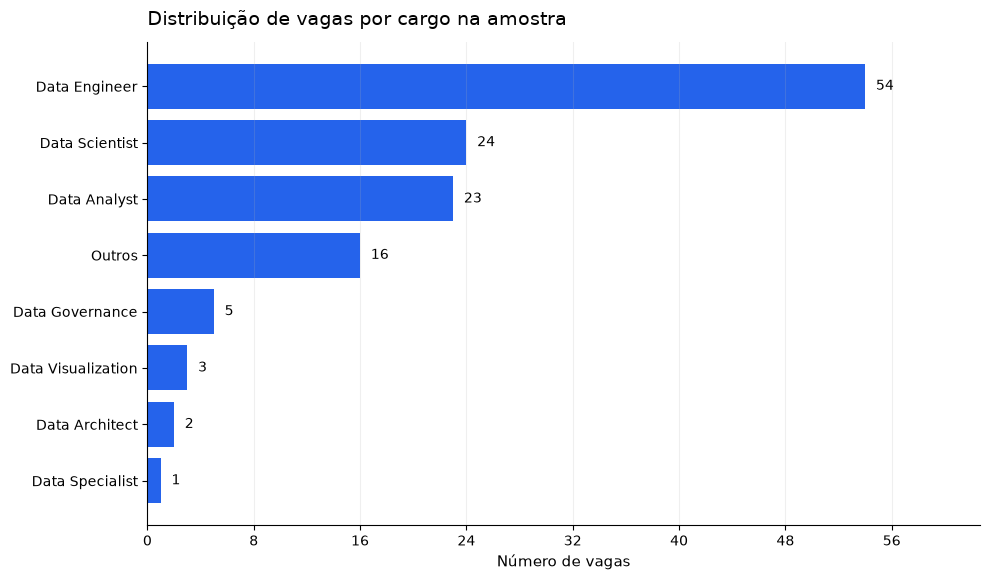

In [18]:
def plotar_barras_horizontais(serie, titulo, xlabel, nome_arquivo):
    dados = serie.dropna().sort_values()
    if dados.empty:
        print(f"Sem dados para gerar: {titulo}")
        return

    fig, ax = plt.subplots(figsize=(10, max(4, 0.55 * len(dados) + 1.5)))
    ax.barh(dados.index.astype(str), dados.values, color="#2563EB")
    ax.set_title(titulo, loc="left", pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="x", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    deslocamento = max(float(dados.max()) * 0.015, 0.08)
    for indice, valor in enumerate(dados.values):
        ax.text(valor + deslocamento, indice, f"{int(valor)}", va="center")

    ax.set_xlim(0, max(float(dados.max()) * 1.16, 1))
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / nome_arquivo, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


contagem_cargos = dataset_analise["cargo_base"].value_counts()
plotar_barras_horizontais(
    contagem_cargos,
    "Distribuição de vagas por cargo na amostra",
    "Número de vagas",
    "distribuicao_cargos.png",
)

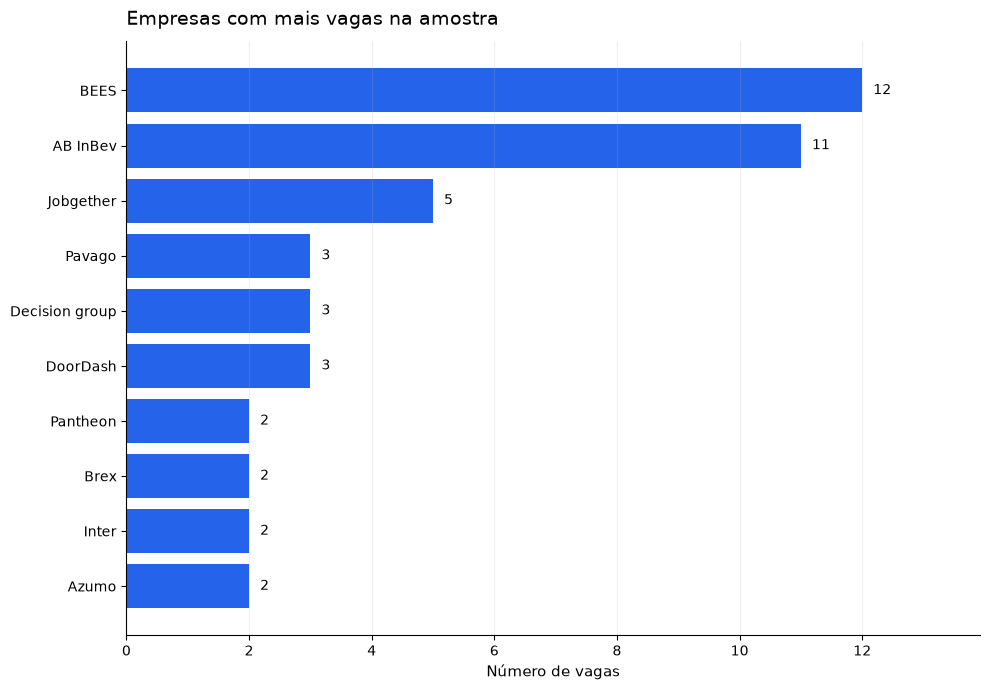

In [19]:
contagem_empresas = (
    dataset_analise["empresa"]
    .fillna("Não informada")
    .value_counts()
    .head(10)
)
plotar_barras_horizontais(
    contagem_empresas,
    "Empresas com mais vagas na amostra",
    "Número de vagas",
    "principais_empresas.png",
)

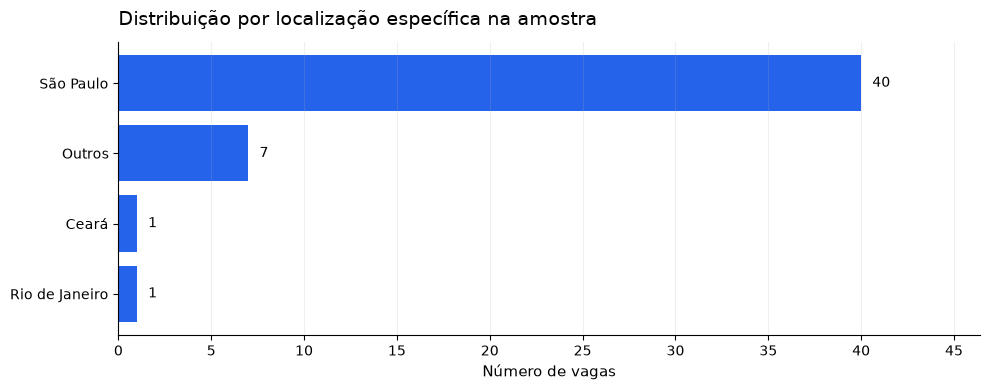

In [20]:
contagem_localizacoes = (
    dataset_analise.loc[
        dataset_analise["localizacao_base"] != "Brasil / Não especificado",
        "localizacao_base",
    ]
    .value_counts()
)
plotar_barras_horizontais(
    contagem_localizacoes,
    "Distribuição por localização específica na amostra",
    "Número de vagas",
    "distribuicao_localizacoes.png",
)

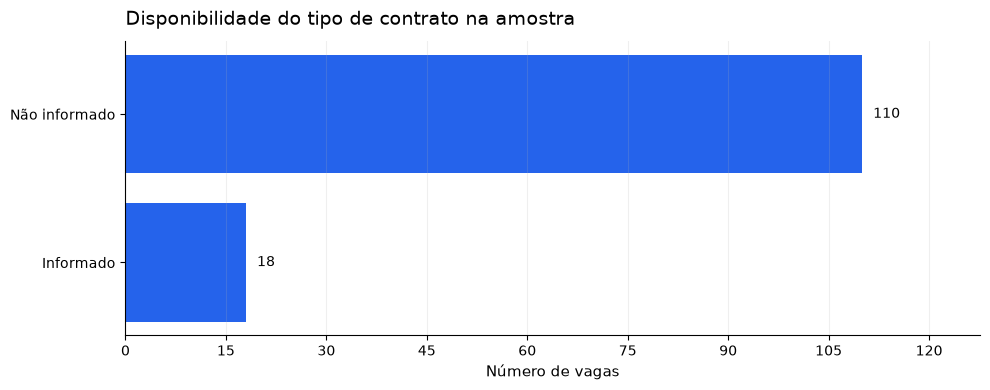

In [21]:
disponibilidade_contrato = pd.Series({
    "Informado": int(dataset_analise["contract_type"].notna().sum()),
    "Não informado": int(dataset_analise["contract_type"].isna().sum()),
})
plotar_barras_horizontais(
    disponibilidade_contrato,
    "Disponibilidade do tipo de contrato na amostra",
    "Número de vagas",
    "disponibilidade_contrato.png",
)

## 16. Salvamento do dataset processado

O dataset analítico é salvo com URLs sanitizadas. A pasta de destino já foi criada na configuração.

In [22]:
arquivo_saida = DATA_PROCESSED_DIR / "jobs_analysis.csv"
dataset_analise.to_csv(arquivo_saida, index=False)

print(f"Dataset salvo em: {arquivo_saida.relative_to(PROJECT_ROOT)}")
print(f"Formato final: {dataset_analise.shape}")
print(f"Execução concluída em: {datetime.now(timezone.utc).isoformat(timespec='seconds')}")

Dataset salvo em: data\processed\jobs_analysis.csv
Formato final: (128, 13)
Execução concluída em: 2026-10-26T01:02:32+00:00


### Limitações da v1

- A busca usa apenas o termo `data` e pode incluir falsos positivos ou deixar vagas relevantes de fora.
- A API retorna descrições truncadas, o que limita análises de skills.
- Contrato, salário, empresa e localização podem estar ausentes ou pouco detalhados.
- As classificações são baseadas em regras de texto e devem ser interpretadas como aproximações.
- Todas as conclusões dizem respeito à amostra coletada, não ao mercado brasileiro inteiro.